In [43]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict


In [44]:
class Quad(TypedDict):
    a : int
    b : int 
    c : int 
    discriminant : int
    equation : str

    


In [45]:
def display_equation(state:Quad):
    a = state['a']
    b = state['b']
    c = state['c']
    return {"equation": f"The quadratic equation is: {a}x^2 + {b}x + {c} = 0"}

In [46]:
def calculate_discriminant(state:Quad):
    a = state['a']
    b = state['b']
    c = state['c']
    discriminant = b**2 - 4*a*c
    return {"discriminant": discriminant}

def select_next_state(state:Quad)-> Literal["two_real_roots", "one_real_root", "no_real_roots"]:
    discriminant = state['discriminant']
    if discriminant > 0:
        return "two_real_roots"
    elif discriminant == 0:
        return "one_real_root"
    else:
        return "no_real_roots"

NameError: name 'Literal' is not defined

In [ ]:
def two_real_roots(state:Quad):
    r = -state['b'] + (state['b']**2 - 4*state['a']*state['c'])**0.5 / (2*state['a'])
    r1 = -state['b'] - (state['b']**2 - 4*state['a']*state['c'])**0.5 / (2*state['a'])
    return {'equation': state['equation'], 'discriminant': state['discriminant'], 'root1': r, 'root2': r1}

def one_real_root(state:Quad):
    r = -state['b'] / (2*state['a'])
    return {'equation': state['equation'], 'discriminant': state['discriminant'], 'root': r}

def no_real_roots(state:Quad):
    return {'equation': 'no real roots exist'}

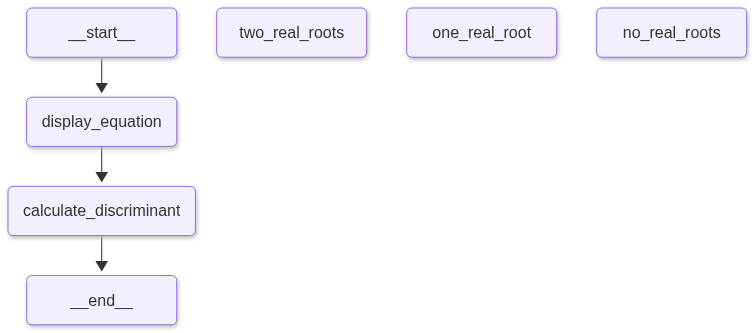

In [ ]:
graph=StateGraph(Quad)

graph.add_node('display_equation',display_equation)
graph.add_node('calculate_discriminant',calculate_discriminant)
graph.add_node('two_real_roots',two_real_roots)
graph.add_node('one_real_root',one_real_root)
graph.add_node('no_real_roots',no_real_roots)


graph.add_edge(START,'display_equation')
graph.add_edge('display_equation','calculate_discriminant') 
graph.add_conditional_edges('calculate_discriminant',select_next_state)


graph.add_edge ('two_real_roots',END)
graph.add_edge ('one_real_root',END)
graph.add_edge ('no_real_roots',END)

workflow=graph.compile()

workflow


In [ ]:
initial_state = {
    'a': 1,
    'b': 2,
    'c': 1
}

workflow.invoke(initial_state)

{'a': 1,
 'b': 2,
 'c': 1,
 'discriminant': 0,
 'equation': 'The quadratic equation is: 1x^2 + 2x + 1 = 0'}